# Lab 3 — Estimating Ticket Resolution Time
Comparing linear regression, polynomial regression, Ridge and Lasso on `lab_ticket_resolution.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Task 1 — Load and inspect the data

In [2]:
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [3]:
df.head()

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


## Task 2 — Define X and y

`y = resolution_hours`. The model is meant to predict resolution time when a ticket arrives.

| Column | Available at prediction time? | Used? |
|---|---|---|
| `ticket_id` | Yes, but it is only a row identifier with no predictive meaning | No |
| `complexity_score` | Yes, estimated when the ticket is triaged | Yes |
| `team_experience_years` | Yes, known when the ticket is assigned | Yes |
| `reopened` | Yes. Whether the incoming ticket is a reopened ticket is known when it arrives | Yes |
| `lines_changed` | **No.** It is only known after the fix has been written | **No (leakage)** |

In [4]:
FEATURES = ["complexity_score", "team_experience_years", "reopened"]
X = df[FEATURES]
y = df["resolution_hours"]

## Task 3 — Train/test split
80/20 split with `random_state=42`. Model settings are chosen with 5-fold cross-validation on the training set only.
The test set is used only to report final metrics.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print(X_train.shape, X_test.shape)

def evaluate(model):
    pred = model.predict(X_test)
    return {"MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)}

results = {}

(192, 3) (48, 3)


## Task 4 — Baseline

In [6]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
results["Dummy (mean)"] = evaluate(dummy)
results["Dummy (mean)"]

{'MAE': 9.113951822916667,
 'RMSE': np.float64(10.597684800766308),
 'R2': -0.021016765260001957}

## Task 5 — Linear Regression

In [7]:
lin = LinearRegression().fit(X_train, y_train)
results["Linear"] = evaluate(lin)
print(results["Linear"])
print(pd.Series(lin.coef_, index=FEATURES))

{'MAE': 2.5905403654464023, 'RMSE': np.float64(3.2191529044356684), 'R2': 0.9057906326651208}
complexity_score         2.964289
team_experience_years   -0.341998
reopened                 4.184232
dtype: float64


## Task 6 — Polynomial regression (degrees 2 and 3), compared with CV on the training set

In [8]:
poly_cv = {}
for degree in [2, 3]:
    pipe = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), LinearRegression())
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    pipe.fit(X_train, y_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
    poly_cv[f"Degree {degree}"] = {"Train RMSE": train_rmse, "CV RMSE (mean)": cv_rmse.mean(), "CV RMSE (std)": cv_rmse.std()}
    results[f"Poly deg {degree}"] = evaluate(pipe)

lin_cv = -cross_val_score(LinearRegression(), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print(f"Linear (reference) CV RMSE: {lin_cv.mean():.3f}")
pd.DataFrame(poly_cv).T.round(3)

Linear (reference) CV RMSE: 3.521


,Train RMSE,CV RMSE (mean),CV RMSE (std)
Degree 2,3.336,3.512,0.290
Degree 3,3.274,3.622,0.232


## Task 7 — Ridge and Lasso with scaling; α selected by CV

In [9]:
ridge_alphas = [0.01, 0.1, 1, 10, 100]
lasso_alphas = [0.001, 0.01, 0.1, 1]
models = {}

for name, Model, alphas in [("Ridge", Ridge, ridge_alphas), ("Lasso", Lasso, lasso_alphas)]:
    rows = []
    for a in alphas:
        pipe = make_pipeline(StandardScaler(), Model(alpha=a, max_iter=100_000))
        cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
        coefs = pipe.fit(X_train, y_train)[-1].coef_
        rows.append({"alpha": a, "CV RMSE": cv_rmse, **dict(zip(FEATURES, coefs))})
    table = pd.DataFrame(rows).set_index("alpha")
    best_alpha = table["CV RMSE"].idxmin()
    models[name] = make_pipeline(StandardScaler(), Model(alpha=best_alpha, max_iter=100_000)).fit(X_train, y_train)
    results[name] = evaluate(models[name])
    print(f"{name}: selected alpha = {best_alpha}")
    display(table.round(3))

scaled_lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
print("Unregularized linear coefficients (scaled features):")
print(pd.Series(scaled_lin[-1].coef_, index=FEATURES).round(3))

Ridge: selected alpha = 0.01


,CV RMSE,complexity_score,team_experience_years,reopened
alpha,,,,
0.01,3.521,8.657,-1.159,1.759
0.10,3.521,8.653,-1.158,1.759
1.00,3.522,8.612,-1.154,1.758
10.00,3.568,8.232,-1.108,1.747
100.00,4.982,5.727,-0.791,1.514


Lasso: selected alpha = 0.001


,CV RMSE,complexity_score,team_experience_years,reopened
alpha,,,,
0.001,3.521,8.656,-1.158,1.758
0.010,3.522,8.649,-1.149,1.750
0.100,3.528,8.576,-1.057,1.670
1.000,3.911,7.846,-0.136,0.870


Unregularized linear coefficients (scaled features):
complexity_score         8.657
team_experience_years   -1.159
reopened                 1.759
dtype: float64


## Test-set results

In [10]:
results_df = pd.DataFrame(results).T
print("Lowest MAE :", results_df["MAE"].idxmin())
print("Lowest RMSE:", results_df["RMSE"].idxmin())
results_df.round(3)

Lowest MAE : Linear
Lowest RMSE: Linear


,MAE,RMSE,R2
Dummy (mean),9.114,10.598,-0.021
Linear,2.591,3.219,0.906
Poly deg 2,2.782,3.553,0.885
Poly deg 3,2.823,3.625,0.881
Ridge,2.591,3.219,0.906
Lasso,2.591,3.219,0.906


## Task 8 — Observed vs. predicted and residual plots

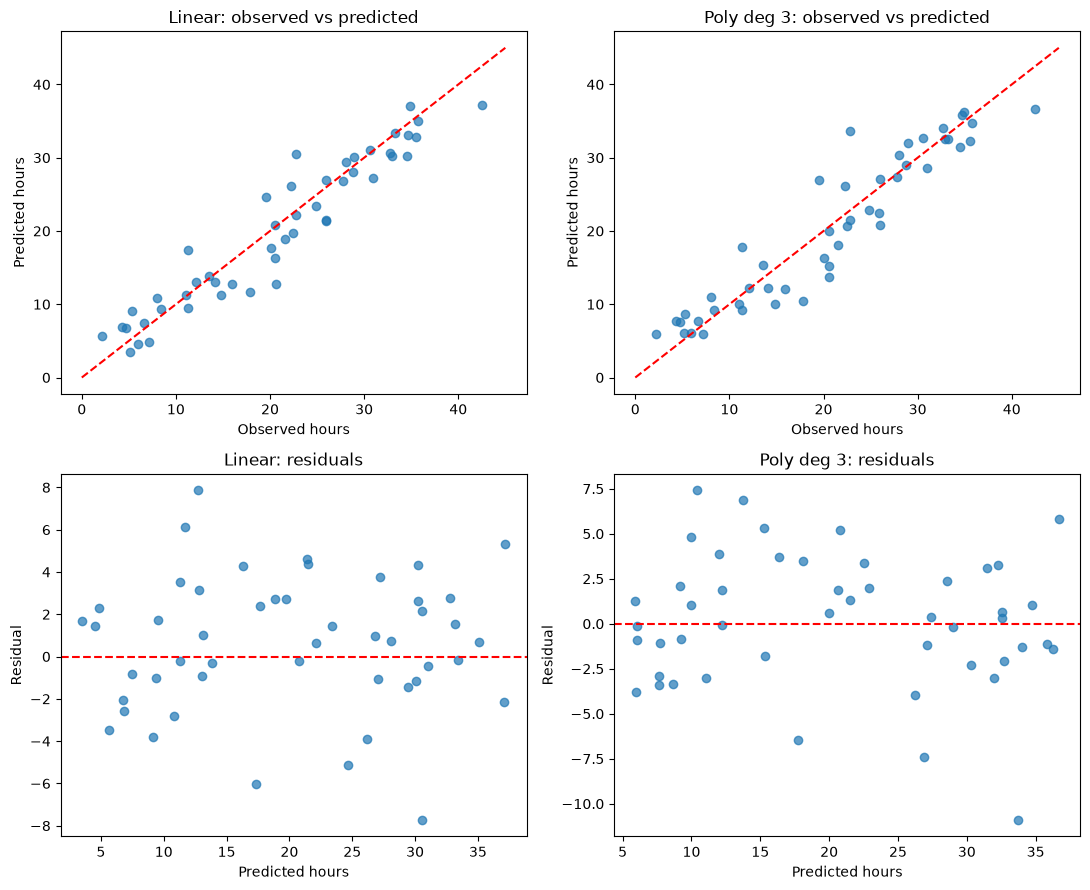

In [11]:
plot_models = {"Linear": lin, "Poly deg 3": make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train, y_train)}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, (name, model) in enumerate(plot_models.items()):
    pred = model.predict(X_test)
    resid = y_test - pred
    axes[0, j].scatter(y_test, pred, alpha=0.7)
    axes[0, j].plot([0, 45], [0, 45], "r--")
    axes[0, j].set(xlabel="Observed hours", ylabel="Predicted hours", title=f"{name}: observed vs predicted")
    axes[1, j].scatter(pred, resid, alpha=0.7)
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set(xlabel="Predicted hours", ylabel="Residual", title=f"{name}: residuals")
plt.tight_layout()
plt.show()

**Observations:**
* **Curvature:** the linear model's residuals scatter around zero across the full prediction range, with no U or
  arch pattern, so a linear form is adequate.
* **Changing spread:** the spread of residuals is roughly the same at low and high predictions, with no funnel shape.
* **Outliers:** a few tickets have residuals of roughly ±6–8 hours under the linear model. The degree-3 model does
  not fix them and makes the worst one larger (about −11 h), which is a sign that the extra flexibility hurts
  rather than helps.

## Task 9 — Recommendation
**Linear Regression** (on `complexity_score`, `team_experience_years`, `reopened`).
* It cuts error far below the mean baseline: test MAE drops from about 9.1 h to about 2.6 h, and R² rises from about 0 to about 0.91.
* Polynomial degree 2 gives practically the same CV RMSE (the difference is far smaller than the CV standard
  deviation). Degree 3 is worse on CV. Neither is better on the test set.
* Ridge and Lasso selected the smallest α in their grids. Their coefficients and errors are almost identical to plain
  linear regression, so regularization adds nothing here.
* The residual plots show no curvature or changing spread that a more complex model would need to capture.
* Linear regression is the simplest and easiest to interpret: about +3 h per complexity point, about −0.3 h per
  year of team experience, and about +4 h if the ticket was reopened.

**Further data or checks needed:** validation on real (not synthetic) tickets, time-based and team/customer-based
splits, more prediction-time features (ticket type, priority, component), and prediction intervals rather than
single-point estimates.

## Analysis questions

**10. Why is the mean baseline useful even though it ignores all features?**
It shows the error you get without any model. A model's MAE, RMSE and R² only mean something compared with that
reference. A model that cannot clearly beat it is not learning anything useful. A model that beats it by an
implausible margin may be leaking information.

**11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?**
See the printout above the test-set results table. Linear, Ridge and Lasso are practically tied (MAE ≈ 2.59 h,
RMSE ≈ 3.22 h), because the selected α values are so small. In this case the same model wins both metrics.
They can differ because MAE weights all errors equally, while RMSE squares errors and so penalises a few large
misses more heavily. A model with smaller typical errors but a few large ones can win on MAE and lose on RMSE.

**12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?**
No meaningful improvement. Degree 2's CV RMSE is within about 0.01 h of linear regression, and degree 3 is worse.
The evidence of overfitting is that **training RMSE keeps falling as the degree rises while CV RMSE gets worse at
degree 3**, so the gap between training and validation error widens. Test error is also higher for both
polynomial models than for linear regression.

**13. How did regularization affect performance and coefficient magnitudes?**
At the selected α values (the smallest in each grid), the coefficients and errors are almost the same as plain
linear regression. With only three useful features the model was not overfitting, so there was nothing to remove.
The α tables show what stronger regularization does. Ridge shrinks all coefficients smoothly toward zero
(e.g. `complexity_score` goes from about 8.7 to 5.7 at α = 100). Lasso shrinks them and pushes weaker ones toward
zero (`team_experience_years` goes from about −1.16 to −0.14 at α = 1). In both cases CV RMSE gets worse, which is
under-fitting.

**14. Why is scaling included in the Ridge/Lasso pipeline?**
The penalty acts on coefficient size, and coefficient size depends on each feature's units. Without scaling,
features on large scales are penalised less than features on small scales, for no meaningful reason.
Standardising puts all features on the same scale so the penalty treats them fairly. Keeping the scaler inside
the pipeline means it is fitted only on the training folds, so no information leaks from validation or test data.

**15. Identify one potential leakage issue in the dataset and explain how you handled it.**
`lines_changed` is only known after the fix has been made, and the same work that drives resolution time also
determines it. It would not be available when a new ticket needs an estimate. I excluded it from X.

**16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams?**
No. With data spanning several years, a random split trains on future tickets and tests on past ones, which hides
changes over time. A time-based split (train on earlier, test on later) is more realistic. With repeated customers
or teams, the same group would appear in both train and test, which inflates scores. A group-based split such as
`GroupKFold` keeps each group on one side only.

**17. What additional tests would you perform before deploying this model?**
* Validate on real ticket data using time-based and group-based splits.
* Confirm every feature is reliably available at prediction time.
* Check errors by segment (team, complexity level) for systematic bias.
* Check that prediction intervals are well calibrated.
* Monitor the model for drift after deployment.